# Noise Modelling

In [1]:
from pathlib import Path

REPO_DIR = Path.cwd()
while not (REPO_DIR / 'pyproject.toml').exists():
    REPO_DIR = REPO_DIR.parent
print(f'Repository root: {REPO_DIR}')

Repository root: /home/andreas/workspaces/brainweb-mri-denoising-benchmark


In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from brainweb_denoising.degradation import (
    add_awgn, add_rician_noise, add_salt_and_pepper, add_gaussian_blur, add_periodic_interference,
)
from brainweb_denoising.io import load_nifti, save_processed_volume

In [3]:
SOURCE = (REPO_DIR / 'data/raw/nifti/T1_ICBM_normal_1mm_pn0_rf0.nii.gz')
SEED = 2026

source=T1_ICBM_normal_1mm_pn0_rf0.nii.gz, max=1196.65, sigma=35.9


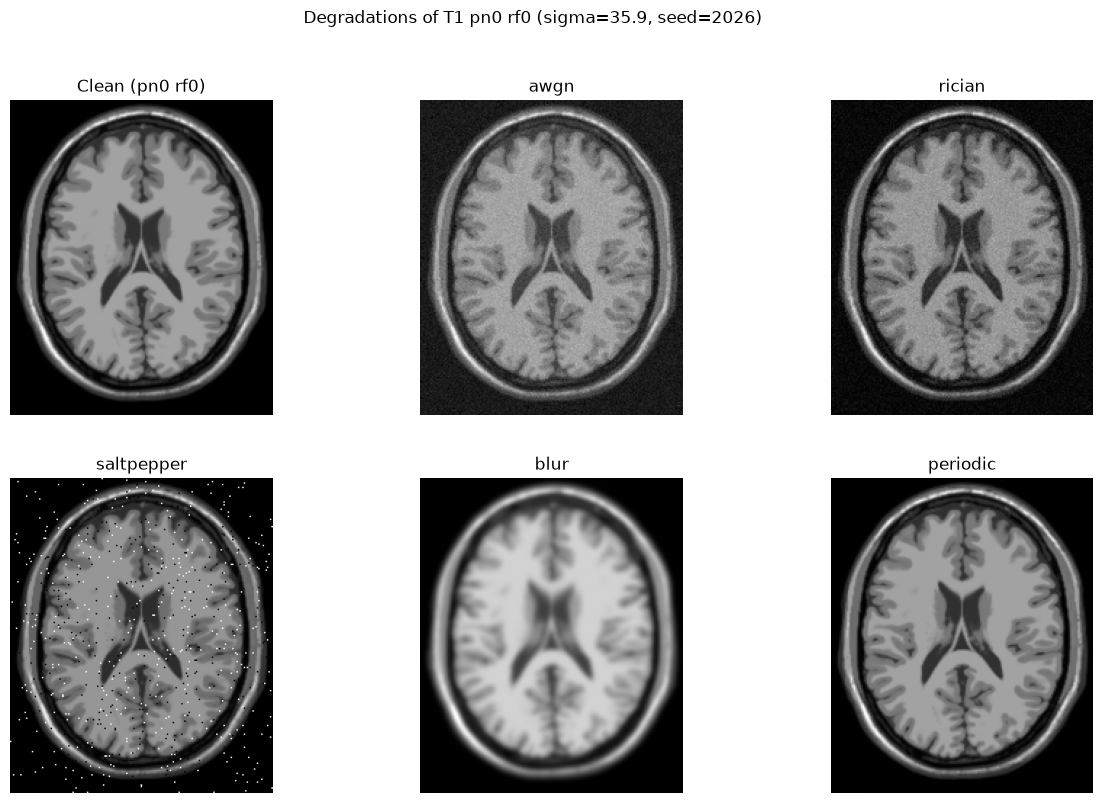

In [4]:
image = load_nifti(SOURCE)
volume = image.get_fdata()
sigma = round(0.03 * float(np.nanmax(volume)), 2)  # 3% of the intensity maximum
print(f'source={SOURCE.name}, max={float(np.nanmax(volume)):.2f}, sigma={sigma}')

degradations = {
    'awgn': lambda v: add_awgn(v, sigma, seed=SEED),
    'rician': lambda v: add_rician_noise(v, sigma, seed=SEED),
    'saltpepper': lambda v: add_salt_and_pepper(v, 0.02, seed=SEED),
    'blur': lambda v: add_gaussian_blur(v, sigma=1.5),
    'periodic': lambda v: add_periodic_interference(v, amplitude=50.0, frequency=0.08, axis=2, phase=0.0),
}

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes[0, 0].imshow(volume[:, :, volume.shape[2] // 2].T, cmap='gray', origin='lower')
axes[0, 0].set(title='Clean (pn0 rf0)')
for ax, (name, degrade) in zip(axes.flat[1:], degradations.items()):
    noisy = degrade(volume)
    save_processed_volume(noisy, image, (REPO_DIR / f'data/degraded/T1_pn0_rf0_{name}.nii.gz'), overwrite=True)
    ax.imshow(noisy[:, :, noisy.shape[2] // 2].T, cmap='gray', origin='lower')
    ax.set(title=name)
for ax in axes.flat:
    ax.axis('off')
fig.suptitle(f'Degradations of T1 pn0 rf0 (sigma={sigma}, seed={SEED})')
fig.savefig(REPO_DIR / 'results/figures/degradation_comparison.png', dpi=150, bbox_inches='tight')
plt.show()